### 📥 Cómo ejecutar este proyecto

1. Abrí el notebook en Google Colab (o cloná el repo).
2. Ejecutá todas las celdas: el dataset se descarga automáticamente desde Kaggle con `kagglehub`.

# 🎮 Exploratory Data Analysis of Gaming Behavior

## Objetivo
Analizar los hábitos de juego y explorar la relación entre variables demográficas, tiempo de juego y niveles de ansiedad utilizando Python.

---

### Dataset
[Online Gaming Anxiety Data (Kaggle)](https://www.kaggle.com/datasets/divyansh22/online-gaming-anxiety-data)
---

### Herramientas
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-Learn
- Statsmodels
- KaggleHub



### Hallazgos principales
- Las horas de juego y la edad explican ≈ 1 % de la variación en ansiedad (R² = 0,01).
- Sumando fobia social (SPIN) y satisfacción con la vida (SWL) el R² sube a ≈ 0,28.
- La regresión lineal y Random Forest rinden igual; se prefiere la lineal por simplicidad.
- Es un análisis observacional de una encuesta voluntaria: no implica causalidad ni sirve como diagnóstico.

In [108]:
!pip install -q kagglehub

import os
import pandas as pd
import kagglehub

# Descarga el dataset desde Kaggle (sin depender de tu Drive)
ruta = kagglehub.dataset_download("divyansh22/online-gaming-anxiety-data")
print(os.listdir(ruta))  # para confirmar el nombre exacto del archivo

df = pd.read_csv(os.path.join(ruta, "GamingStudy_data.csv"), encoding="latin1")
display(df.head())

Using Colab cache for faster access to the 'online-gaming-anxiety-data' dataset.
['GamingStudy_data.csv']


,S. No.,Timestamp,GAD1,GAD2,GAD3,GAD4,GAD5,GAD6,GAD7,GADE,...,Birthplace,Residence,Reference,Playstyle,accept,GAD_T,SWL_T,SPIN_T,Residence_ISO3,Birthplace_ISO3
0,1,42052.00437,0,0,0,0,1,0,0,Not difficult at all,...,USA,USA,Reddit,Singleplayer,Accept,1,23,5.0,USA,USA
1,2,42052.00680,1,2,2,2,0,1,0,Somewhat difficult,...,USA,USA,Reddit,Multiplayer - online - with strangers,Accept,8,16,33.0,USA,USA
2,3,42052.03860,0,2,2,0,0,3,1,Not difficult at all,...,Germany,Germany,Reddit,Singleplayer,Accept,8,17,31.0,DEU,DEU
3,4,42052.06804,0,0,0,0,0,0,0,Not difficult at all,...,USA,USA,Reddit,Multiplayer - online - with online acquaintanc...,Accept,0,17,11.0,USA,USA
4,5,42052.08948,2,1,2,2,2,3,2,Very difficult,...,USA,South Korea,Reddit,Multiplayer - online - with strangers,Accept,14,14,13.0,KOR,USA


In [109]:
# Ver cuántas filas nulas hay por columna
print("--- Valores Faltantes por Columna ---")
print(df.isnull().sum())

# Ver el tipo de datos (Dtype) de cada columna
print("\n--- Estructura de los Datos ---")
print(df.info())

--- Valores Faltantes por Columna ---
S. No.                 0
Timestamp              0
GAD1                   0
GAD2                   0
GAD3                   0
GAD4                   0
GAD5                   0
GAD6                   0
GAD7                   0
GADE                 649
SWL1                   0
SWL2                   0
SWL3                   0
SWL4                   0
SWL5                   0
Game                   0
Platform               0
Hours                 30
earnings               0
whyplay                0
League              1852
highestleague      13464
streams              100
SPIN1                124
SPIN2                154
SPIN3                140
SPIN4                159
SPIN5                166
SPIN6                156
SPIN7                138
SPIN8                144
SPIN9                158
SPIN10               160
SPIN11               187
SPIN12               168
SPIN13               187
SPIN14               156
SPIN15               147
SPIN16      

In [110]:
# @title
# Columnas numéricas clave que queremos analizar
columnas_numericas = ['GAD_T', 'Hours', 'SWL_T', 'SPIN_T', 'Age']

for col in columnas_numericas:
    if col in df.columns:
        # errors='coerce' convierte los textos inválidos en NaN
        df[col] = pd.to_numeric(df[col], errors='coerce')

print("¡Columnas convertidas a numéricas!")

¡Columnas convertidas a numéricas!


In [111]:
# @title
# Opción A: Borramos filas donde GAD_T u Hours sean nulos (son críticas para el análisis)
df_clean = df.dropna(subset=['GAD_T', 'Hours']).copy()

# Opción B: Si faltan edades, rellenamos con la mediana
if 'Age' in df_clean.columns:
    mediana_edad = df_clean['Age'].median()
    df_clean['Age'] = df_clean['Age'].fillna(mediana_edad)

print(f"Tamaño original: {df.shape[0]} filas.")
print(f"Tamaño después de limpiar nulos: {df_clean.shape[0]} filas.")

Tamaño original: 13464 filas.
Tamaño después de limpiar nulos: 13434 filas.


In [112]:
# @title
# Ver cuántos duplicados hay
duplicados = df_clean.duplicated().sum()
print(f"Filas duplicadas encontradas: {duplicados}")

# Si hay, los borramos
if duplicados > 0:
    df_clean = df_clean.drop_duplicates()
    print("Duplicados eliminados.")

Filas duplicadas encontradas: 0


In [113]:
# @title
# Una semana tiene 168 horas en total. Alguien que dice jugar más de 100 horas semanales es un outlier extremo.
# Filtramos para quedarnos con datos lógicos.
df_clean = df_clean[df_clean['Hours'] <= 100]

# Filtramos edades lógicas (ej. entre 10 y 80 años)
df_clean = df_clean[(df_clean['Age'] >= 10) & (df_clean['Age'] <= 80)]

print(f"Tamaño final tras remover outliers: {df_clean.shape[0]} filas.")

Tamaño final tras remover outliers: 13420 filas.


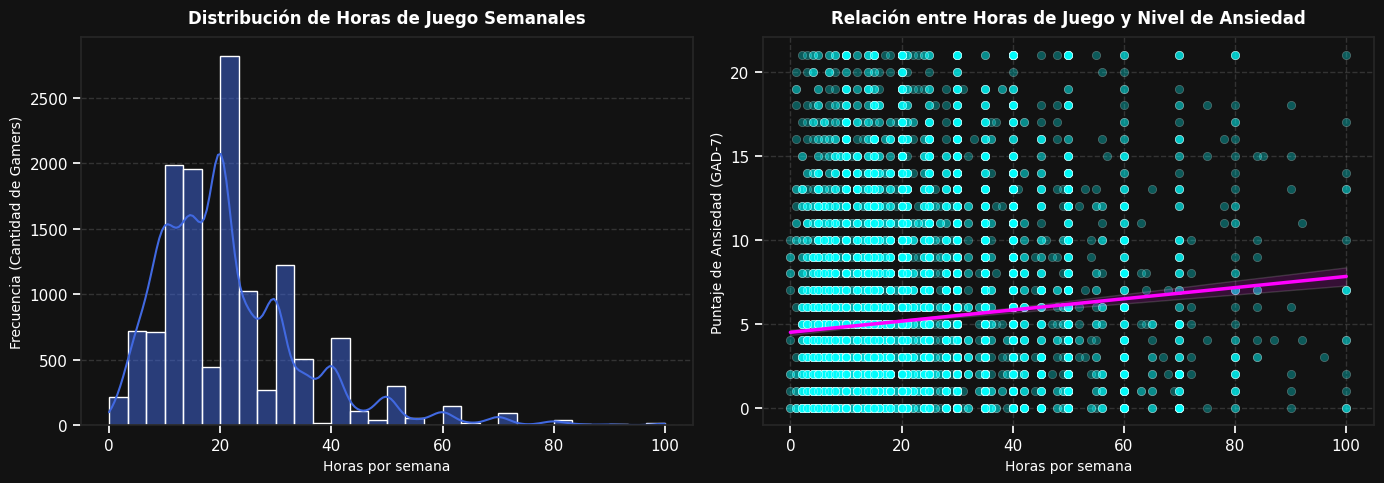

In [114]:
# @title
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuración de estilo estético con fondo negro
# Usamos 'dark_background' de matplotlib como base y luego ajustamos Seaborn
plt.style.use('dark_background')
sns.set_theme(style="ticks", palette="muted") # Usamos "ticks" para evitar la cuadrícula blanca de "whitegrid" en fondo oscuro

# Ajustes visuales específicos para fondo negro
plt.rcParams['figure.facecolor'] = '#121212' # Un negro ligeramente más suave
plt.rcParams['axes.facecolor'] = '#121212'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'
plt.rcParams['figure.figsize'] = (14, 6) # Ajusta el tamaño de los gráficos




# ------------------------------------------------------------------
# GRÁFICO 1: Histograma de las Horas de Juego Semanales
# ------------------------------------------------------------------
plt.figure(figsize=(14, 5))

# Creamos una cuadrícula de 1 fila y 2 columnas para poner los gráficos lado a lado
plt.subplot(1, 2, 1)

sns.histplot(
    data=df_clean,
    x='Hours',
    kde=True,          # Agrega la línea de tendencia de distribución suave
    color='royalblue', # Un azul que resalta bien en negro
    bins=30,           # Cantidad de barras en el gráfico
    line_kws={'color': 'white'} # La línea KDE será blanca para contrastar
)
plt.title("Distribución de Horas de Juego Semanales", fontsize=12, fontweight='bold', pad=10, color='white')
plt.xlabel("Horas por semana", fontsize=10, color='white')
plt.ylabel("Frecuencia (Cantidad de Gamers)", fontsize=10, color='white')
plt.grid(axis='y', color='gray', linestyle='--', alpha=0.3) # Una cuadrícula muy sutil

# ------------------------------------------------------------------
# GRÁFICO 2: Scatterplot (Dispersión) entre Horas de Juego y Ansiedad
# ------------------------------------------------------------------
plt.subplot(1, 2, 2)

sns.scatterplot(
    data=df_clean,
    x='Hours',
    y='GAD_T',
    alpha=0.3,         # Puntos más transparentes para que no saturen el fondo oscuro
    color='cyan'       # Un color cian brillante que resalta en negro
)

# Agregamos una línea de tendencia lineal para ver la dirección de la relación
sns.regplot(
    data=df_clean,
    x='Hours',
    y='GAD_T',
    scatter=False,     # No dibuja los puntos de nuevo, solo la línea
    color='magenta',   # Una línea de tendencia color magenta brillante
    line_kws={"linewidth": 2.5}
)

plt.title("Relación entre Horas de Juego y Nivel de Ansiedad", fontsize=12, fontweight='bold', pad=10, color='white')
plt.xlabel("Horas por semana", fontsize=10, color='white')
plt.ylabel("Puntaje de Ansiedad (GAD-7)", fontsize=10, color='white')
plt.grid(color='gray', linestyle='--', alpha=0.3) # Cuadrícula sutil en ambos ejes

# Ajustar diseño para que no se superpongan los textos
plt.tight_layout()
plt.show()

## ¿A qué edad y quiénes juegan más?

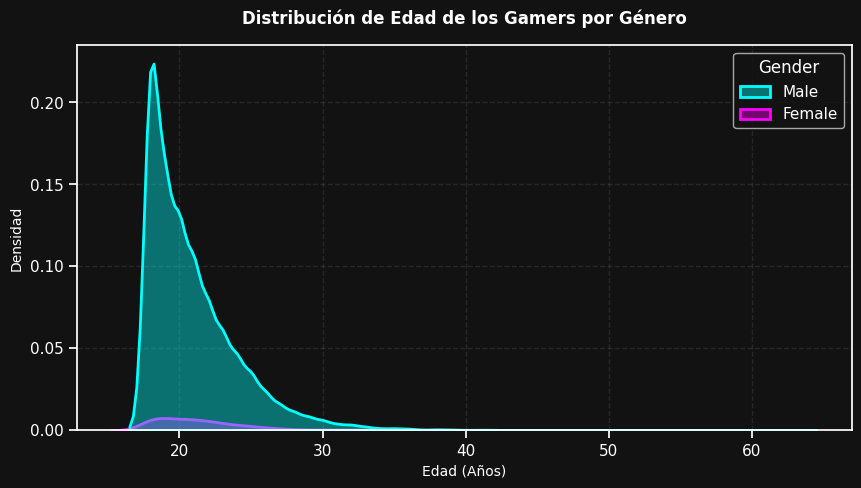

In [115]:
# @title
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de fondo negro
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#121212'
plt.rcParams['axes.facecolor'] = '#121212'


plt.figure(figsize=(10, 5))

# Graficamos la distribución de edad según el Género (filtrando los principales)
df_gender = df_clean[df_clean['Gender'].isin(['Male', 'Female'])]

sns.kdeplot(
    data=df_gender,
    x='Age',
    hue='Gender',
    fill=True,
    palette={'Male': 'cyan', 'Female': 'magenta'},
    alpha=0.4,
    linewidth=2
)

plt.title("Distribución de Edad de los Gamers por Género", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Edad (Años)", fontsize=10)
plt.ylabel("Densidad", fontsize=10)
plt.grid(color='gray', linestyle='--', alpha=0.2)

plt.show()

##Gráfico del promedio de Ansiedad, según rango etáreo

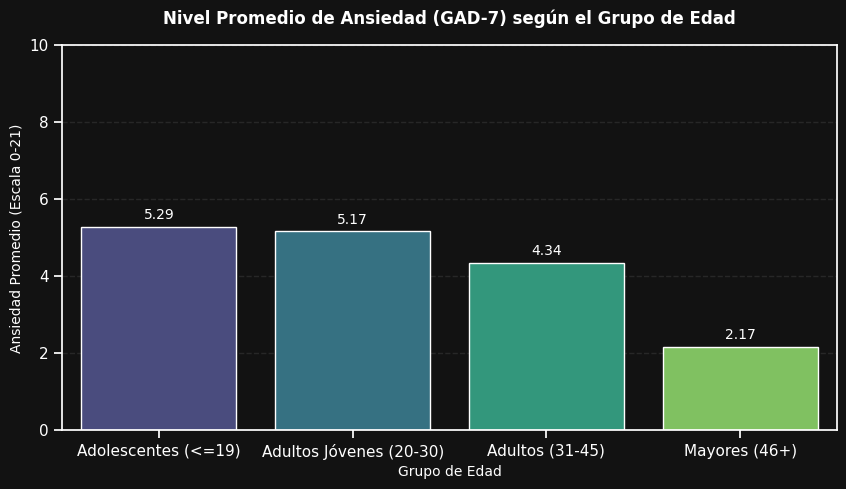

In [116]:
# @title
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rangos = [0, 19, 30, 45, 100]
etiquetas = ['Adolescentes (<=19)', 'Adultos Jóvenes (20-30)', 'Adultos (31-45)', 'Mayores (46+)']

# Creamos la columna de grupo de edad
df_clean['Age_Group'] = pd.cut(df_clean['Age'], bins=rangos, labels=etiquetas)

# Calculamos la ansiedad promedio por cada grupo de edad
df_grouped = df_clean.groupby('Age_Group', observed=False)['GAD_T'].mean().reset_index()

#  Gráfico de barras con fondo negro
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_grouped,
    x='Age_Group',
    y='GAD_T',
    palette='viridis', # Una paleta degradada que queda genial en fondo oscuro
    hue='Age_Group',
    legend=False
)

plt.title("Nivel Promedio de Ansiedad (GAD-7) según el Grupo de Edad", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Grupo de Edad", fontsize=10)
plt.ylabel("Ansiedad Promedio (Escala 0-21)", fontsize=10)
plt.ylim(0, 10) # Ajustamos el límite vertical para apreciar mejor las diferencias
plt.grid(axis='y', color='gray', linestyle='--', alpha=0.2)

# Mostrar los valores numéricos exactos arriba de cada barra
for index, row in df_grouped.iterrows():
    plt.text(index, row['GAD_T'] + 0.2, f"{row['GAD_T']:.2f}", color='white', ha="center", fontsize=10)

plt.show()

## ¿Los jugadores desempleados o estudiantes juegan más por tener más tiempo libre? ¿Eso impacta en su ansiedad?

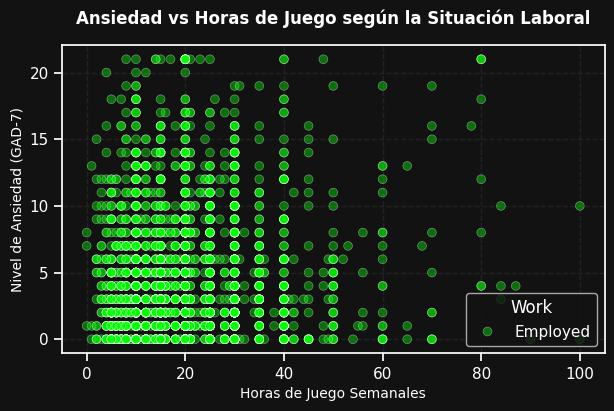

In [117]:
# @title
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#121212'
plt.rcParams['axes.facecolor'] = '#121212'



# Filtramos para quedarnos con las 3 categorías principales de trabajo para limpiar el gráfico
df_work = df_clean[df_clean['Work'].isin(['Student', 'Employed', 'Unemployed'])]

plt.figure(figsize=(7, 4))

# Gráfico de dispersión segmentado por situación laboral
sns.scatterplot(
    data=df_work,
    x='Hours',
    y='GAD_T',
    hue='Work',
    palette={'Student': 'cyan', 'Employed': 'lime', 'Unemployed': 'magenta'},
    alpha=0.4,
    s=40
)

plt.title("Ansiedad vs Horas de Juego según la Situación Laboral", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Horas de Juego Semanales", fontsize=10)
plt.ylabel("Nivel de Ansiedad (GAD-7)", fontsize=10)
plt.grid(color='gray', linestyle='--', alpha=0.15)

plt.show()

##¿Varía el nivel de fobia social (SPIN_T) dependiendo de si el usuario juega en PC, Consola o Celular?


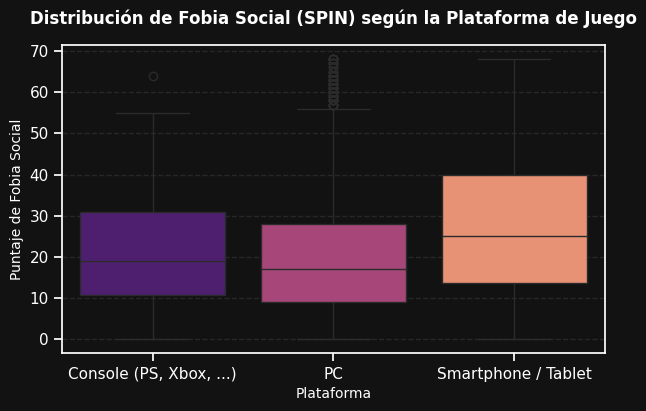

In [118]:
# @title
plt.figure(figsize=(7, 4))

# Filtramos las plataformas con suficientes datos para que sea representativo
plataformas_principales = df_clean['Platform'].value_counts().iloc[:3].index
df_plat = df_clean[df_clean['Platform'].isin(plataformas_principales)]

sns.boxplot(
    data=df_plat,
    x='Platform',
    y='SPIN_T',
    palette='magma',
    hue='Platform',
    legend=False
)

plt.title("Distribución de Fobia Social (SPIN) según la Plataforma de Juego", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Plataforma", fontsize=10)
plt.ylabel("Puntaje de Fobia Social", fontsize=10)
plt.grid(axis='y', color='gray', linestyle='--', alpha=0.2)

plt.show()

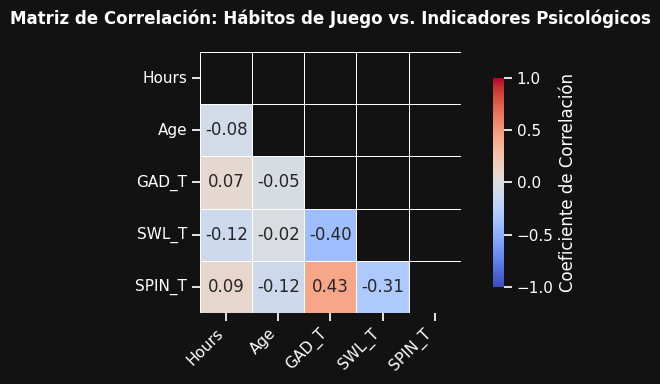

In [119]:
# @title
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuración del estilo fondo oscuro estático
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#121212'
plt.rcParams['axes.facecolor'] = '#121212'


# 2. Seleccionamos las variables numéricas
columnas_analisis = ['Hours', 'Age', 'GAD_T', 'SWL_T', 'SPIN_T']

# Eliminamos filas que tengan nulos en estas columnas para que la matemática no falle
df_sub = df_clean[columnas_analisis].dropna()

# Calculamos la correlación de Spearman
matriz_corr = df_sub.corr(method='spearman')

# 3. Creamos la máscara para ocultar la mitad de arriba (así queda mucho más limpio)
mask = np.triu(np.ones_like(matriz_corr, dtype=bool))

# 4. Graficamos con Seaborn
plt.figure(figsize=(7, 4))

sns.heatmap(
    matriz_corr,
    mask=mask,
    annot=True,          # Pone los números en cada celda
    fmt=".2f",           # Redondea a 2 decimales
    cmap="coolwarm",     # Paleta térmica tradicional
    vmin=-1, vmax=1,     # Límites de la correlación
    square=True,         # Hace que las celdas sean cuadradas perfectas
    linewidths=.5,       # Separa las celdas con una línea sutil
    cbar_kws={"shrink": .8, "label": "Coeficiente de Correlación"}
)

plt.title("Matriz de Correlación: Hábitos de Juego vs. Indicadores Psicológicos", fontsize=12, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

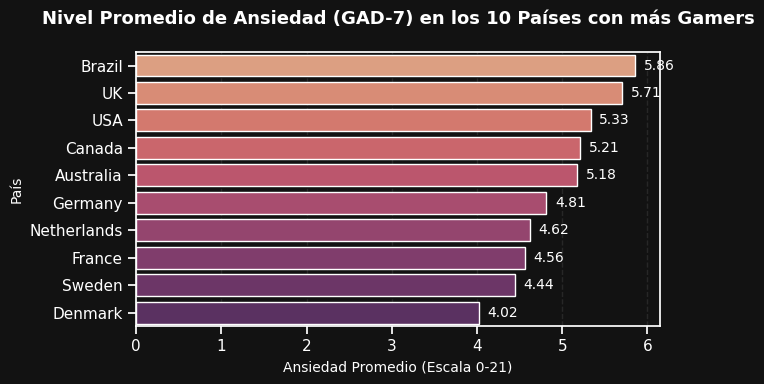

In [120]:
# @title
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuración de estilo fondo oscuro
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#121212'
plt.rcParams['axes.facecolor'] = '#121212'
plt.rcParams['text.color'] = 'white'



# 2. Obtener los 10 países con más respuestas para que el análisis sea representativo
top_paises = df_clean['Residence'].value_counts().head(10).index

# Filtramos el dataset solo con esos 10 países
df_top_paises = df_clean[df_clean['Residence'].isin(top_paises)]

# 3. Calcular la ansiedad promedio (GAD_T) por país y ordenarlos de mayor a menor
df_grouped_country = df_top_paises.groupby('Residence')['GAD_T'].mean().reset_index()
df_grouped_country = df_grouped_country.sort_values(by='GAD_T', ascending=False)

# 4. Crear el gráfico de barras horizontales
plt.figure(figsize=(7, 4))

sns.barplot(
    data=df_grouped_country,
    x='GAD_T',
    y='Residence',
    palette='flare', # Una paleta degradada neón que va de tonos rojizos a morados
    hue='Residence',
    legend=False
)

# Ajustes de títulos y etiquetas
plt.title("Nivel Promedio de Ansiedad (GAD-7) en los 10 Países con más Gamers", fontsize=13, fontweight='bold', pad=20)
plt.xlabel("Ansiedad Promedio (Escala 0-21)", fontsize=10)
plt.ylabel("País", fontsize=10)

# Líneas de cuadrícula verticales sutiles para ayudar a leer los valores
plt.grid(axis='x', color='gray', linestyle='--', alpha=0.2)

# Colocar el valor numérico exacto al final de cada barra
for index, row in enumerate(df_grouped_country.itertuples()):
    plt.text(row.GAD_T + 0.1, index, f"{row.GAD_T:.2f}", color='white', va='center', fontsize=10)

plt.tight_layout()
plt.show()

In [121]:
# @title
import pandas as pd


# Contar cuántas veces aparece 'Argentina' en la columna 'Residence'
argentina_count = df_clean[df_clean['Residence'] == 'Argentina'].shape[0]

if argentina_count > 0:
    print(f"Sí, 'Argentina' se encuentra en los datos de residencia con {argentina_count} entradas.")
else:
    print("No, 'Argentina' no se encuentra en los datos de residencia.")


Sí, 'Argentina' se encuentra en los datos de residencia con 104 entradas.


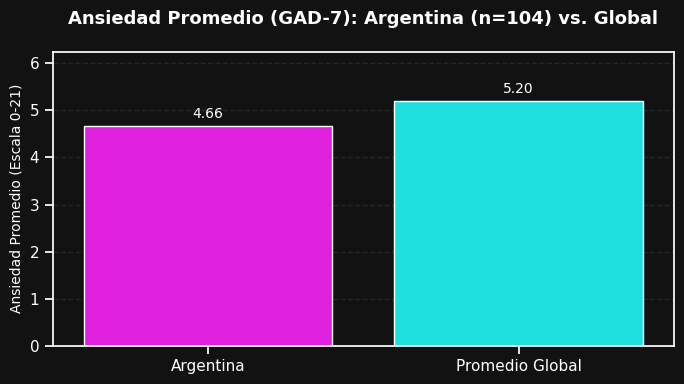

In [122]:
# @title
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Calcular la ansiedad promedio para Argentina
argentina_count = (df_clean['Residence'] == 'Argentina').sum()
argentina_avg_gad = df_clean[df_clean['Residence'] == 'Argentina']['GAD_T'].mean()

# Calcular la ansiedad promedio global
overall_avg_gad = df_clean['GAD_T'].mean()

# Crear un DataFrame para el gráfico
data_to_plot = pd.DataFrame({
    'Categoría': ['Argentina', 'Promedio Global'],
    'GAD_T Promedio': [argentina_avg_gad, overall_avg_gad]
})

# Configuración de estilo fondo oscuro
plt.style.use('dark_background')
plt.rcParams['figure.facecolor'] = '#121212'
plt.rcParams['axes.facecolor'] = '#121212'
plt.rcParams['text.color'] = 'white'

plt.figure(figsize=(7, 4))
sns.barplot(
    data=data_to_plot,
    x='Categoría',
    y='GAD_T Promedio',
    palette=['magenta', 'cyan'], # Colores que resaltan en fondo oscuro
    hue='Categoría',
    legend=False
)

plt.title(f'Ansiedad Promedio (GAD-7): Argentina (n={argentina_count}) vs. Global', fontsize=13, fontweight='bold', pad=20)
plt.xlabel('', fontsize=10)
plt.ylabel('Ansiedad Promedio (Escala 0-21)', fontsize=10)
plt.ylim(0, max(argentina_avg_gad, overall_avg_gad) * 1.2) # Ajustar límite y para mejor visualización
plt.grid(axis='y', color='gray', linestyle='--', alpha=0.2)

# Añadir los valores numéricos exactos en las barras
for index, row in data_to_plot.iterrows():
    plt.text(index, row['GAD_T Promedio'] + 0.1, f"{row['GAD_T Promedio']:.2f}", color='white', ha="center", va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

Como complemento del análisis exploratorio, se construyó un modelo predictivo para estimar el nivel de ansiedad (GAD_T) a partir de variables relevantes.

## Modelado predictivo de la ansiedad (GAD_T)
 Dos preguntas:
- *Modelo A:* ¿Podemos estimar la ansiedad con hábitos de juego y datos demográficos (Hours, Age)?
- *Modelo B:* ¿Mejora la estimación al sumar indicadores psicológicos (SPIN_T, SWL_T)?

In [123]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error

vars_A = ['Hours', 'Age']
vars_B = ['Hours', 'Age', 'SPIN_T', 'SWL_T']
objetivo = 'GAD_T'

# Mismas filas para todos los modelos (así la comparación es justa)
datos = df_clean[vars_B + [objetivo]].dropna()
y = datos[objetivo]

# Un único split para todo el modelado
idx_train, idx_test = train_test_split(
    datos.index, test_size=0.20, random_state=42
)
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

print(f"Filas utilizables: {len(datos)}")
print(f"Train: {len(idx_train)} | Test: {len(idx_test)}")

Filas utilizables: 12773
Train: 10218 | Test: 2555


In [124]:
# Aporte de cada combinación de variables (regresión lineal, evaluado en test)
combinaciones = {
    'Hours + Age': ['Hours', 'Age'],
    'Solo SPIN_T': ['SPIN_T'],
    'Solo SWL_T': ['SWL_T'],
    'Hours + Age + SPIN_T': ['Hours', 'Age', 'SPIN_T'],
    'Todas (Hours, Age, SPIN_T, SWL_T)': ['Hours', 'Age', 'SPIN_T', 'SWL_T']
}

resultados_comb = []

for nombre, variables in combinaciones.items():
    modelo = LinearRegression()
    modelo.fit(datos.loc[idx_train, variables], y_train)
    predicciones = modelo.predict(datos.loc[idx_test, variables])

    resultados_comb.append({
        'Variables': nombre,
        'R2_test': r2_score(y_test, predicciones),
        'RMSE_test': mean_squared_error(y_test, predicciones) ** 0.5
    })

tabla_comb = pd.DataFrame(resultados_comb)
print(tabla_comb.round(4).to_string(index=False))

                        Variables  R2_test  RMSE_test
                      Hours + Age   0.0146     4.7062
                      Solo SPIN_T   0.2093     4.2157
                       Solo SWL_T   0.1537     4.3614
             Hours + Age + SPIN_T   0.2150     4.2004
Todas (Hours, Age, SPIN_T, SWL_T)   0.2831     4.0142


## Comparación de modelos A y B (evaluado SOLO en test)

In [125]:
modelos = {
    'Referencia (promedio)': DummyRegressor(strategy='mean'),
    'Lineal': LinearRegression(),
    'Random Forest': RandomForestRegressor(
        n_estimators=100, max_depth=6, random_state=42
    ),
}
conjuntos = {'Modelo A (Hours, Age)': vars_A,
             'Modelo B (+ SPIN_T, SWL_T)': vars_B}

resultados = []
for nombre_conj, cols in conjuntos.items():
    X_tr, X_te = datos.loc[idx_train, cols], datos.loc[idx_test, cols]
    for nombre_mod, mod in modelos.items():
        mod.fit(X_tr, y_train)
        pred = mod.predict(X_te)
        resultados.append({
            'Conjunto': nombre_conj,
            'Modelo': nombre_mod,
            'R2_test': r2_score(y_test, pred),
            'RMSE_test': mean_squared_error(y_test, pred) ** 0.5,
        })

tabla = pd.DataFrame(resultados)
print(tabla.round(4).to_string(index=False))

                  Conjunto                Modelo  R2_test  RMSE_test
     Modelo A (Hours, Age) Referencia (promedio)  -0.0011     4.7435
     Modelo A (Hours, Age)                Lineal   0.0146     4.7062
     Modelo A (Hours, Age)         Random Forest   0.0095     4.7182
Modelo B (+ SPIN_T, SWL_T) Referencia (promedio)  -0.0011     4.7435
Modelo B (+ SPIN_T, SWL_T)                Lineal   0.2831     4.0142
Modelo B (+ SPIN_T, SWL_T)         Random Forest   0.2892     3.9970


## Validación cruzada (5 particiones) para confirmar

In [126]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

for nombre_conj, cols in conjuntos.items():
    print(f"\n=== {nombre_conj} ===")
    for nombre_mod in ['Lineal', 'Random Forest']:
        mod = (LinearRegression() if nombre_mod == 'Lineal'
               else RandomForestRegressor(n_estimators=100, max_depth=6,
                                          random_state=42))
        scores = cross_val_score(mod, datos[cols], y, cv=cv, scoring='r2')
        print(f"{nombre_mod:14s} R² medio: {scores.mean():.4f} "
              f"(± {scores.std():.4f})")


=== Modelo A (Hours, Age) ===
Lineal         R² medio: 0.0099 (± 0.0039)
Random Forest  R² medio: 0.0038 (± 0.0055)

=== Modelo B (+ SPIN_T, SWL_T) ===
Lineal         R² medio: 0.2813 (± 0.0099)
Random Forest  R² medio: 0.2821 (± 0.0091)


## Modelo final: OLS con p-valores y coeficientes estandarizado

In [127]:
import statsmodels.api as sm

X_train_B = datos.loc[idx_train, vars_B]

# (a) Coeficientes en unidades originales + p-valores
ols = sm.OLS(y_train, sm.add_constant(X_train_B)).fit()
print(ols.summary())

# (b) Coeficientes estandarizados: permiten comparar el "peso" de cada variable
X_std = (X_train_B - X_train_B.mean()) / X_train_B.std()
y_std = (y_train - y_train.mean()) / y_train.std()
ols_std = sm.OLS(y_std, sm.add_constant(X_std)).fit()

print("\n=== Coeficientes estandarizados (comparables entre variables) ===")
print(ols_std.params.drop('const').round(4).sort_values(key=abs, ascending=False))

                            OLS Regression Results                            
Dep. Variable:                  GAD_T   R-squared:                       0.281
Model:                            OLS   Adj. R-squared:                  0.281
Method:                 Least Squares   F-statistic:                     999.0
Date:                Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:07:46   Log-Likelihood:                -28584.
No. Observations:               10218   AIC:                         5.718e+04
Df Residuals:                   10213   BIC:                         5.721e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          6.3815      0.315     20.251      0.0

## Ejemplo de predicción (con el modelo lineal B entrenado en train)

In [128]:
modelo_final = LinearRegression().fit(datos.loc[idx_train, vars_B], y_train)

jugador = pd.DataFrame({'Hours': [40], 'Age': [20],
                        'SPIN_T': [50], 'SWL_T': [18]})
pred = modelo_final.predict(jugador)[0]

print(f"GAD-7 estimado: {pred:.2f}")
print("Referencia: 0-4 mínima | 5-9 leve | 10-14 moderada | 15-21 severa")
print("Esto es una estimación estadística, NO un diagnóstico.")

GAD-7 estimado: 9.36
Referencia: 0-4 mínima | 5-9 leve | 10-14 moderada | 15-21 severa
Esto es una estimación estadística, NO un diagnóstico.


### Conclusiones

- **Modelo A (hábitos + edad):** R² en test = 0,015 (RMSE 4,71) frente a 0,000 del modelo de referencia (RMSE 4,74). En validación cruzada el R² medio es ≈ 0,01. Las horas de juego y la edad **no permiten estimar la ansiedad**: el modelo apenas mejora a predecir siempre el promedio.
- **Modelo B (+ SPIN_T y SWL_T):** R² en test = 0,283 (RMSE 4,01) y R² medio en validación cruzada = 0,281 (± 0,010). Prácticamente todo el poder predictivo proviene de los indicadores psicológicos.
- **Aporte por variable:** solo con SPIN_T el R² es 0,209; solo con SWL_T, 0,154; al sumar Hours y Age a SPIN_T el aumento es mínimo (0,209 → 0,215).
- **Regresión lineal vs. Random Forest:** rinden prácticamente igual (R² en test 0,283 vs. 0,289; en validación cruzada 0,281 vs. 0,282, dentro de la variabilidad entre particiones). Se elige la regresión lineal por ser más simple e interpretable.
- **Coeficientes estandarizados:** SPIN_T (+0,356) y SWL_T (−0,291) pesan mucho más que Hours (+0,015) y Age (−0,002). Ambos indicadores psicológicos son estadísticamente significativos (p < 0,001). Hours no alcanza significancia al 5 % (p = 0,077) y Age tampoco (p = 0,829).
- **Respuesta a la pregunta inicial:** el tiempo de juego casi no aporta información sobre la ansiedad una vez que se consideran otros indicadores. Según el modelo, 10 horas semanales más de juego se asocian con apenas ≈ 0,05 puntos más de GAD-7.

### Limitaciones

- Encuesta online voluntaria (autoselección): no permite inferir causalidad ni generalizar a toda la población gamer.
- SPIN, SWL y GAD miden constructos psicológicos relacionados: parte del poder predictivo refleja solapamiento entre cuestionarios, no un hallazgo sobre hábitos de juego.
- Aun con el Modelo B, el error típico (RMSE ≈ 4 puntos en una escala de 0 a 21) es grande para uso individual; el R² de 0,28 deja sin explicar la mayor parte de la variación.
- Los residuos del OLS no son normales (asimetría ≈ 0,96), por lo que los p-valores deben tomarse como aproximados.
- Muestra de Argentina reducida: el promedio por país debe leerse con cautela.
- Las estimaciones no constituyen un diagnóstico psicológico.